# Basic Exploratory Data Analysis – Crop Yield
**Tasks:** Data loading, basic exploration, data cleaning, analysis, and visualization.

This notebook follows the supplied activity sheet and uses `crop_yield.csv` from the same folder.

## 1. Data Loading & Basic Exploration

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

crop_df = pd.read_csv("crop_yield.csv")

print("Dataset loaded successfully.")
print("Original dataset shape:", crop_df.shape)

Dataset loaded successfully.
Original dataset shape: (3000, 9)


In [2]:
# Display the first 10 rows
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [3]:
# Missing values in each column
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [4]:
# Data types before cleaning
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [5]:
# Statistical summary of numeric columns
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [6]:
# Statistical summary of object (categorical/text) columns
crop_df.describe(include="object")

C:\Users\dell\AppData\Local\Temp\ipykernel_20280\1057394713.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  crop_df.describe(include="object")


,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


## 2. Data Cleaning

In [7]:
# Remove rows where YIELD_KG is missing
crop_df = crop_df.dropna(subset=["YIELD_KG"]).copy()

# Fill missing AREA_ACRES with its mean
crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(
    crop_df["AREA_ACRES"].mean()
)

# Replace missing DISTRICT values
crop_df["DISTRICT"] = crop_df["DISTRICT"].fillna("Unknown")

# Replace missing FERTILIZER_USED values
crop_df["FERTILIZER_USED"] = crop_df["FERTILIZER_USED"].fillna("No")

# Fill missing YIELD_VALUE with its mean
crop_df["YIELD_VALUE"] = crop_df["YIELD_VALUE"].fillna(
    crop_df["YIELD_VALUE"].mean()
)

# Convert HARVEST_DATE to datetime using the format in the activity sheet
crop_df["HARVEST_DATE"] = pd.to_datetime(
    crop_df["HARVEST_DATE"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Remove F from FARM_ID and convert it to integer
crop_df["FARM_ID"] = (
    crop_df["FARM_ID"].astype(str)
    .str.replace("F", "", regex=False)
    .astype(int)
)

print("Data cleaning completed.")
print("Shape after removing missing YIELD_KG rows:", crop_df.shape)

Data cleaning completed.
Shape after removing missing YIELD_KG rows: (2670, 9)


In [8]:
# Re-check missing values after cleaning
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [9]:
# Re-check data types after cleaning
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

## 3. Data Analysis and Visualization

In [10]:
# Total YIELD_KG for each crop type
crop_yield = crop_df.groupby("CROP_TYPE").agg(
    {"YIELD_KG": "sum"}
).sort_values("YIELD_KG", ascending=False)

crop_yield

,YIELD_KG
CROP_TYPE,
Wheat,2035500.0
Rice,1638000.0
Maize,1112500.0
Sugarcane,592000.0


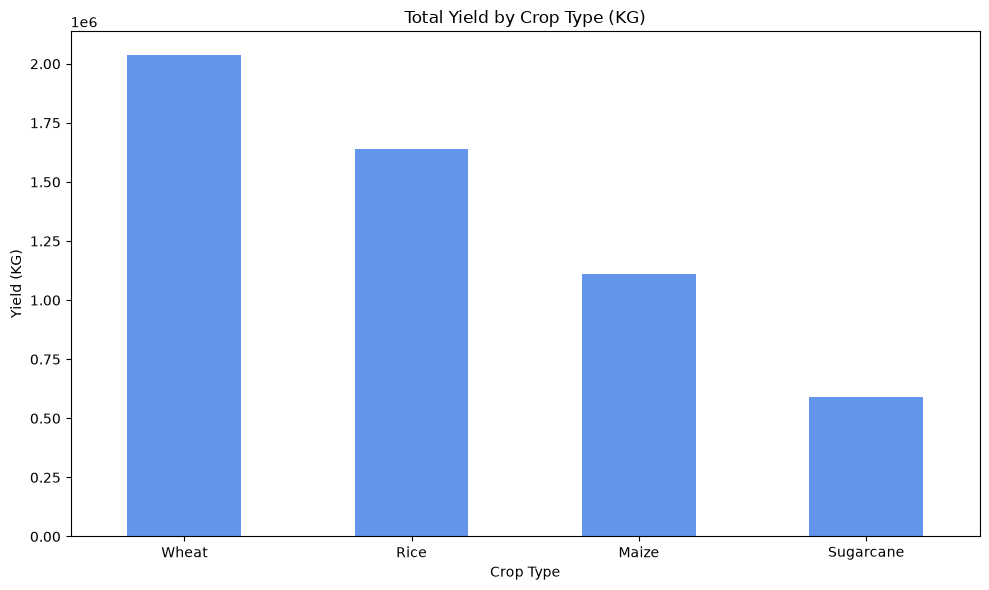

In [11]:
# Bar chart: Total Yield by Crop Type (KG)
ax = crop_yield.plot(
    kind="bar",
    figsize=(10, 6),
    legend=False,
    color="cornflowerblue"
)

ax.set_title("Total Yield by Crop Type (KG)")
ax.set_xlabel("Crop Type")
ax.set_ylabel("Yield (KG)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Pivot table: total yield by harvest date
yield_pivot = crop_df.pivot_table(
    values="YIELD_KG",
    index="HARVEST_DATE",
    aggfunc="sum"
)

yield_pivot

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


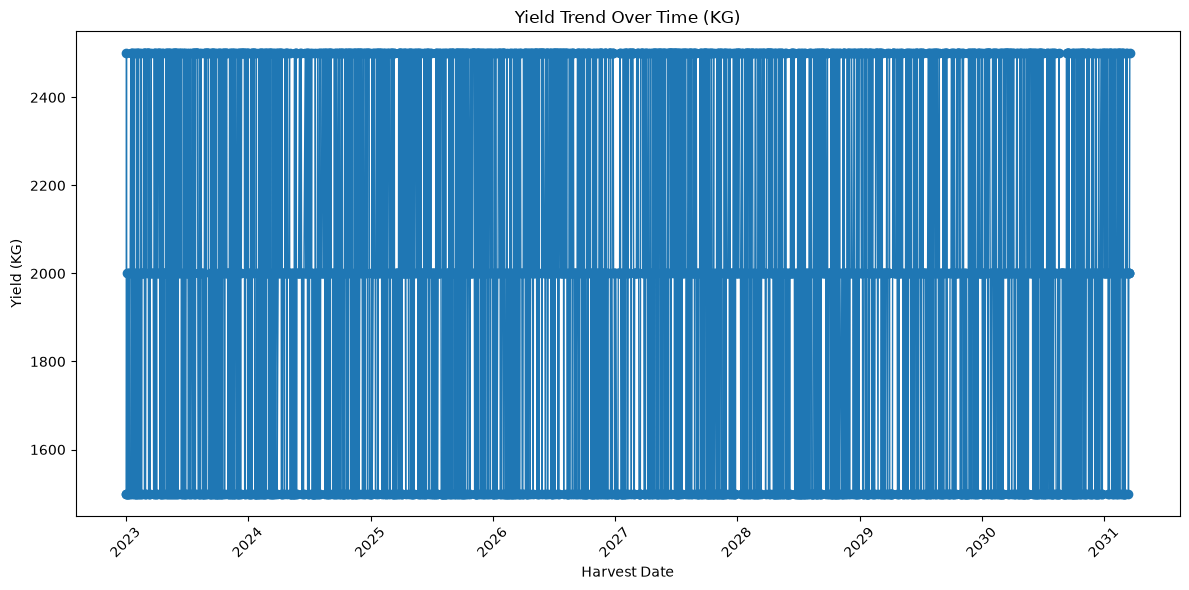

In [13]:
# Line chart: yield trend over time; save the figure
plt.figure(figsize=(12, 6))
plt.plot(
    yield_pivot.index,
    yield_pivot["YIELD_KG"],
    marker="o",
    linewidth=1
)

plt.title("Yield Trend Over Time (KG)")
plt.xlabel("Harvest Date")
plt.ylabel("Yield (KG)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("crop_yield_trend.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Final Checks

In [14]:
print("FINAL DATASET INFORMATION")
print("-------------------------")
print("Rows:", len(crop_df))
print("Columns:", len(crop_df.columns))
print("\nMissing values:")
print(crop_df.isnull().sum())
print("\nData types:")
print(crop_df.dtypes)
print("\nTotal yield by crop type:")
print(crop_yield)
print("\nAnalysis completed successfully.")

FINAL DATASET INFORMATION
-------------------------
Rows: 2670
Columns: 9

Missing values:
FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

Data types:
FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

Total yield by crop type:
            YIELD_KG
CROP_TYPE           
Wheat      2035500.0
Rice       1638000.0
Maize      1112500.0
Sugarcane   592000.0

Analysis completed successfully.
